# TP Integrador · Leer texto (impreso y manuscrito) en imágenes con modelos de Hugging Face

**Materia:** Seminario de Actualización · Tec. Sup. en Cs. de Datos e IA · IFTS N.º 18
**Alumna:** Natalia Nodar
**Docente:** Cynthia M. Villagra

Para ejecutarlo correctamente, ir a README.md

---
# Preparación del entorno

## Instalación

Con `pipeline`, **el modelo corre en la computadora donde se ejecuta el notebook**. Si la máquina tiene placa de video NVIDIA, se usa la GPU. Si no, corre en la CPU: funciona, pero es más lento.

Memoria aproximada que necesita cada modelo:
- `LightOnOCR-2-1B`: ~2 GB de pesos → anda bien en cualquier compu con 8 GB de RAM.
- `Qwen3-VL-4B-Instruct`: ~9 GB de pesos → necesita 16 GB de RAM o una GPU con 10+ GB. Si la máquina no alcanza, en la celda 0.2 se puede elegir correrlo con `InferenceClient` (en los servidores de Hugging Face).

> Si tenés GPU NVIDIA, instalá primero PyTorch con soporte CUDA siguiendo https://pytorch.org/get-started/locally/ . Si no, el `torch` común de la celda de abajo alcanza.
>
> `torchvision` hace falta para Qwen3-VL (su procesador de imágenes y video lo usa). Después de instalar, **reiniciar el kernel** (`Restart`) antes de seguir.

In [1]:
%pip install -q torch torchvision "transformers>=5.0.0" accelerate huggingface_hub python-dotenv pillow pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, io, gc, re, time, glob, base64, difflib, unicodedata
from collections import Counter

import torch
import transformers
import huggingface_hub
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import pipeline
from huggingface_hub import InferenceClient

DISPOSITIVO = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (sin GPU)"
print("transformers   :", transformers.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
print("torch          :", torch.__version__)
print("Dónde corre pipeline:", DISPOSITIVO)

c:\Users\natin\Proyectos VS\Seminario actualizacion\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers   : 5.19.0
huggingface_hub: 2.2.0
torch          : 2.14.1+cpu
Dónde corre pipeline: CPU (sin GPU)


## Token de Hugging Face y configuración

`InferenceClient` manda la imagen a los servidores de Hugging Face, así que necesita un **token** que identifique a quien hace el pedido (y al que se le cobran los créditos).

- Se guarda en un archivo **`.env`** (que está en el `.gitignore`) con la línea `HF_TOKEN=hf_...`.
- Si no hay `.env`, la notebook lo pide por teclado sin mostrarlo.

Aca tuve algunos problemas para actualizar el token, porque en primera instancia lo incluí en el código, pero al ser inseguro, debi generarlo nuevamente y guardarlo en .env

In [3]:
from dotenv import load_dotenv

load_dotenv(override=True)                      # lee el .env y le gana a cualquier HF_TOKEN viejo
HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    from getpass import getpass
    HF_TOKEN = getpass("Pegá tu token de Hugging Face (Enter para seguir sin token): ") or None

print("Token cargado:", "sí" if HF_TOKEN else "NO → las celdas de InferenceClient van a fallar")

Token cargado: sí


In [4]:
MODELO_A = "lightonai/LightOnOCR-2-1B"     # el que uso en la app
MODELO_B = "Qwen/Qwen3-VL-4B-Instruct"     # el que uso para comparar
PROVEEDOR = "featherless-ai"               # el proveedor que sirve los dos modelos en Hugging Face

# Qwen necesita que le pida qué hacer; LightOnOCR solo recibe la imagen.
INSTRUCCION = {
    MODELO_A: None,
    MODELO_B: "Transcribí todo el texto de la imagen tal cual aparece, sin agregar nada.",
}

MAX_TOKENS = 1024   # largo máximo de la respuesta (igual para los dos modelos y las dos formas)

# ¿Cómo corro el modelo B en la comparación?
#   "pipeline" → en esta compu (necesita ~10 GB de RAM libres o GPU)
#   "api"      → con InferenceClient, en los servidores de Hugging Face
FORMA_MODELO_B = "pipeline"

## Los modelos candidatos

Datos principales de las *model cards* de cada modelo en Hugging Face:

| | **Modelo A (elegido)** | **Modelo B (para comparar)** |
|---|---|---|
| Nombre | [`lightonai/LightOnOCR-2-1B`](https://huggingface.co/lightonai/LightOnOCR-2-1B) | [`Qwen/Qwen3-VL-4B-Instruct`](https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct) |
| Tarea (*pipeline tag*) | `image-text-to-text` | `image-text-to-text` |
| Tipo | **Especialista** en OCR: está entrenado solo para transcribir documentos | **Generalista** de visión + lenguaje: describe imágenes, responde preguntas y también lee texto |
| Tamaño | ~1.000 millones de parámetros (BF16) | ~4.000 millones de parámetros (BF16) |
| Idiomas | 11 idiomas, con mayor cobertura de francés | OCR en 32 idiomas |
| Datos de entrenamiento | Dataset propio `LightOnOCR-mix-0126` (documentos escaneados, arXiv, más francés) + ajuste con RLVR | Corpus multimodal general de Qwen; la card destaca robustez con poca luz, desenfoque e inclinación |
| ¿Qué recibe? | **Solo la imagen**, sin instrucción | La imagen **+ una instrucción en texto** ("Transcribí…") |
| ¿Menciona manuscritos? | No | No |

LightOnOCR es 4 veces más chico, así que debería ser más rápido y liviano. Qwen3-VL es más grande y fue entrenado con imágenes más variadas, así que podría leer mejor la letra manuscrita y las fotos difíciles. Acá lo que más me interesa es que lea correctamente manuscritos en español. Los dos son multilenguaje, pero ninguno aclara ser especialista en manuscritos.

## Las imágenes de prueba

En mi problema, las entradas son **fotos de texto** que saqué yo, y los **casos difíciles** son fotos con algo que complica la lectura: ángulo, inclinación, otro idioma, letra cursiva.

| Archivo | Qué es | 
|---|---|
| `01_impreso_limpio` | Tapa de un manual de licuadora |
| `02_impreso_ruido` | Folleto en perspectiva, con fotos de fondo |
| `03_impreso_inclinado` | Tapa de revista girada | 
| `04_letra_chica` | Página de un libro en inglés, en baja resolución |
| `05_manuscrito_prolijo` | Tabla escrita a mano en mayúsculas |
| `06_manuscrito_apurado` | Apuntes en cursiva, escritos rápido |
| `07_manuscrito_cursiva` | Página completa de apuntes manuscritos |
| `08_ticket_o_nota` | Cupón de supermercado |

**Mi estrategia para saber si el modelo leyó bien la imagen** Para cada imagen anoto unas pocas **palabras clave** que se ven claramente en la foto. Si el modelo las devuelve, leyó bien; si le faltan, se equivocó en esa parte.

In [5]:
CARPETA_IMAGENES = "imagenes" if os.path.isdir("imagenes") else "."

def buscar_imagen(prefijo):
    # Busca el archivo por su número (01_, 02_, ...) sin importar la extensión (.jpg, .jpeg, .png).
    encontrados = sorted(glob.glob(os.path.join(CARPETA_IMAGENES, prefijo + "*")))
    encontrados = [f for f in encontrados if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    return encontrados[0] if encontrados else None

PRUEBAS = [
    # (prefijo, descripción,                  ¿difícil?, palabras clave que se ven en la foto)
    ("01_", "Impreso: tapa de manual",        False, ["Peabody", "manual de instrucciones", "licuadora de mesa"]),
    ("02_", "Impreso en perspectiva",         True,  ["Grandis", "Tapebicuá", "bosques certificados"]),
    ("03_", "Impreso muy inclinado",          True,  ["Maderas", "Innovación", "madera maciza"]),
    ("04_", "Inglés, baja resolución",        True,  ["Chapter Eight", "Deathday Party"]),
    ("05_", "Manuscrito prolijo (tabla)",     False, ["tipos de bases", "relacional", "redundancia", "escalabilidad"]),
    ("06_", "Manuscrito apurado (cursiva)",   True,  ["inteligencia artificial", "sincronía", "ajedrez"]),
    ("07_", "Manuscrito: página completa",    True,  ["aprendizaje automático", "historia de la IA", "Dartmouth", "robótica"]),
    ("08_", "Ticket de supermercado",         False, ["queso provoleta", "queso azul", "Santa Rosa"]),
]

# Me quedo solo con las imágenes que existen (para que la notebook no se rompa si falta alguna).
PRUEBAS = [(buscar_imagen(pre), desc, dificil, claves) for pre, desc, dificil, claves in PRUEBAS]
faltan = [desc for ruta, desc, *_ in PRUEBAS if ruta is None]
PRUEBAS = [p for p in PRUEBAS if p[0] is not None]
print(f"Carpeta de imágenes: {os.path.abspath(CARPETA_IMAGENES)}")
print(f"Imágenes encontradas: {len(PRUEBAS)}")
if faltan:
    print("⚠️ No encontré:", faltan)

Carpeta de imágenes: c:\Users\natin\Proyectos VS\Seminario actualizacion\TP_Integrador\imagenes
Imágenes encontradas: 8


## Funciones de ayuda

- **`cargar_imagen`**: abre la imagen, la endereza según la orientación que guardó el celular y, si es muy grande, la achica a 1540 px del lado más largo (el tamaño que recomienda la model card de LightOnOCR). A los dos modelos les paso **la misma imagen**, para que la comparación sea justa.
- **`armar_mensaje`**: arma el pedido en formato chat (`role` + `content`), que es el formato que usan los dos modelos.
- **`puntaje`**: qué proporción de las palabras clave aparece en lo que leyó el modelo (0 = ninguna, 1 = todas). No distingue mayúsculas, tildes ni el formato que agrega el modelo (LightOnOCR devuelve Markdown, con `#` o `**`).
- **`veredicto`**: traduce el puntaje en **¿acertó?** → `sí` (encontró todas), `parcial` (la mitad o más) o `no`.

Además de los números, en la tabla se ve el **texto completo que leyó cada modelo**, para revisar a ojo si inventó o se salteó algo.

1.0
0.0


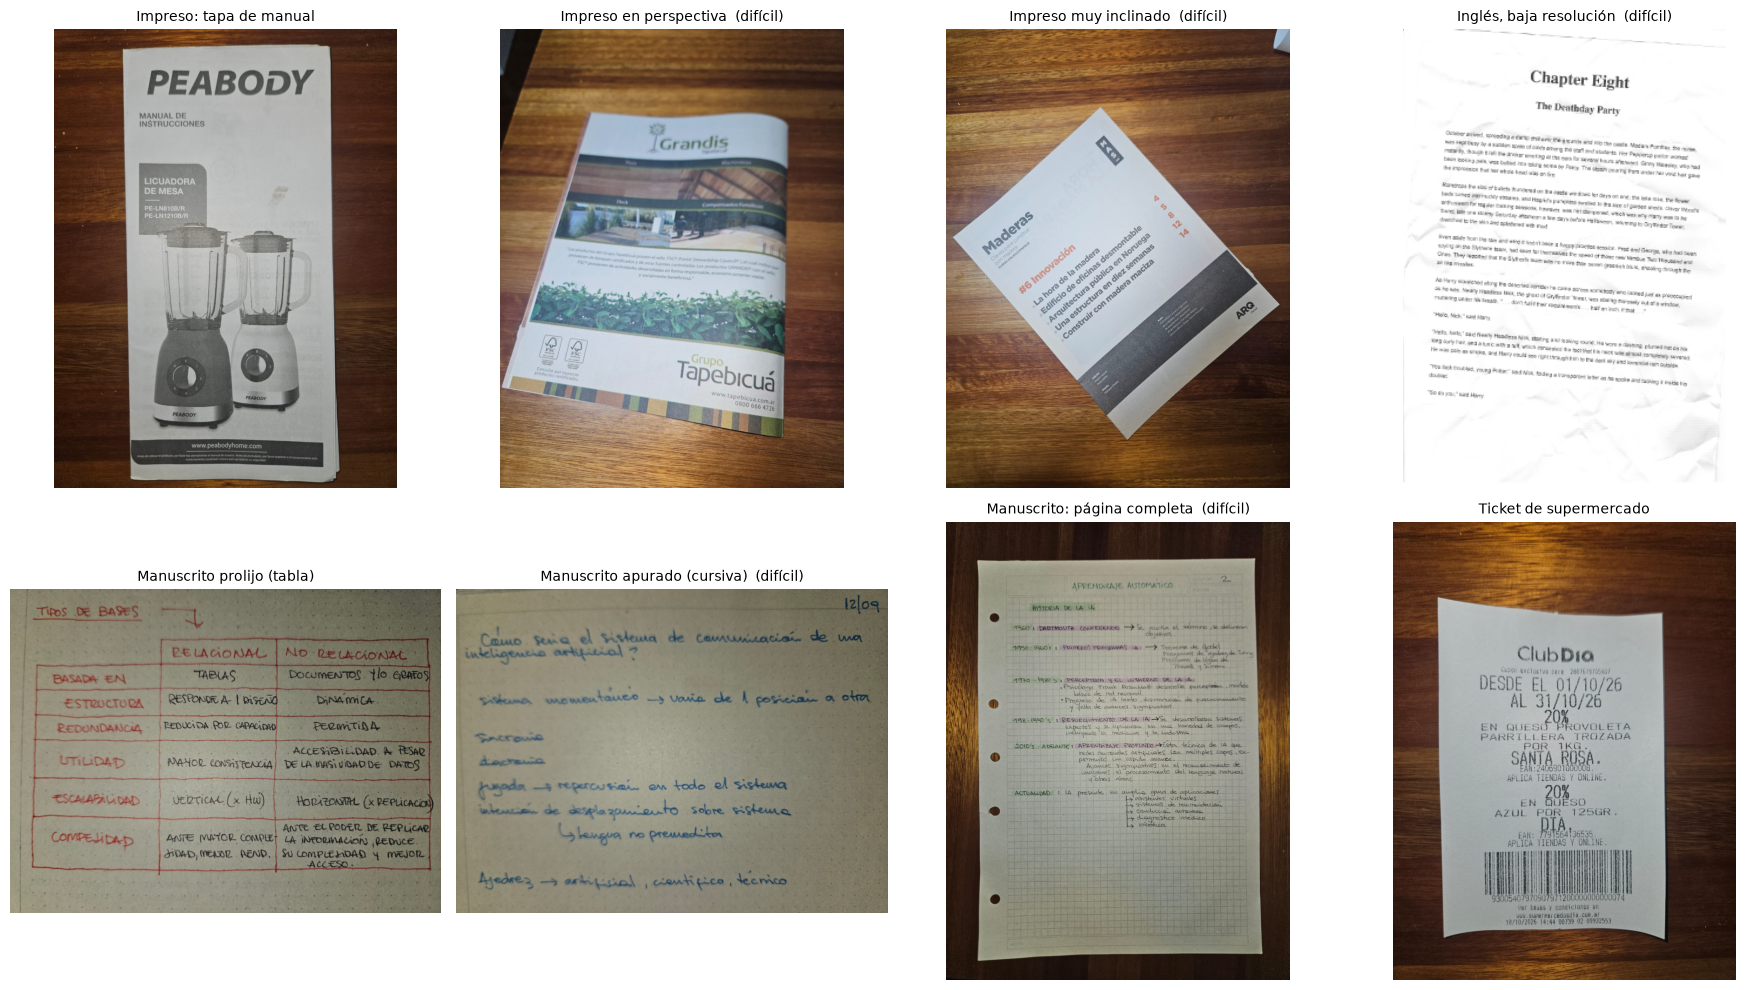

In [6]:
from PIL import ImageOps

LADO_MAX = 1540

def cargar_imagen(ruta):
    img = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    img.thumbnail((LADO_MAX, LADO_MAX))          # achica manteniendo proporción (no agranda)
    return img

def armar_mensaje(modelo, img):
    contenido = [{"type": "image", "image": img}]
    if INSTRUCCION[modelo]:
        contenido.append({"type": "text", "text": INSTRUCCION[modelo]})
    return [{"role": "user", "content": contenido}]

def normalizar(t):
    t = unicodedata.normalize("NFKD", t.lower())
    t = "".join(c for c in t if not unicodedata.combining(c))   # saca tildes
    t = re.sub(r"[^\w]+", " ", t)                                # saca símbolos y puntuación
    return " " + " ".join(t.split()) + " "

def claves_encontradas(leido, claves):
    texto = normalizar(leido)
    return [c for c in claves if normalizar(c) in texto]

def puntaje(leido, claves):
    return round(len(claves_encontradas(leido, claves)) / len(claves), 2)

def veredicto(p):
    return "sí" if p == 1 else ("parcial" if p >= 0.5 else "no")

# Prueba rápida de la función de puntaje
print(puntaje("# MANUAL DE **INSTRUCCIONES** · PEABODY", ["Peabody", "manual de instrucciones"]))  # 1.0
print(puntaje("Manual de instruciones",                   ["Peabody", "manual de instrucciones"]))  # 0.0

# Muestro las imágenes de prueba
fig, ejes = plt.subplots(2, 4, figsize=(18, 10))
for eje in ejes.flat:
    eje.axis("off")
for eje, (ruta, desc, dificil, _) in zip(ejes.flat, PRUEBAS):
    eje.imshow(cargar_imagen(ruta))
    eje.set_title(f"{desc}{'  (difícil)' if dificil else ''}", fontsize=10)
plt.tight_layout(); plt.show()

---
# Comparación de los dos modelos

Con `pipeline`, **los pesos del modelo se descargan del Hub a esta computadora y el modelo corre acá**. La primera vez tarda porque descarga los pesos; después quedan guardados en la caché de Hugging Face (`~/.cache/huggingface`).

Corro un modelo por vez. LightOnOCR queda cargado porque lo uso mas adelante; Qwen, que ocupa casi 9 GB, lo borro de la memoria apenas termina.

Para cada modelo mido:
- **tiempo de carga**: descargar los pesos (solo la primera vez) y cargarlos en memoria;
- **tiempo por imagen**: la inferencia en sí;
- **memoria** que ocupan los pesos.

In [7]:
def fila_resultado(desc, dificil, claves, leido, seg):
    p = puntaje(leido, claves)
    print(f"✔ {desc:<32} {seg:6.1f} s   puntaje={p}")
    return {"imagen": desc, "¿difícil?": "sí" if dificil else "",
            "texto leído": leido,
            "palabras clave encontradas": f"{len(claves_encontradas(leido, claves))} / {len(claves)}",
            "puntaje": p, "¿acertó?": veredicto(p),
            "segundos": round(seg, 2)}

def correr_con_pipeline(pipe, modelo):
    filas = []
    for ruta, desc, dificil, claves in PRUEBAS:
        img = cargar_imagen(ruta)
        t0 = time.perf_counter()
        salida = pipe(text=armar_mensaje(modelo, img),
                      max_new_tokens=MAX_TOKENS,
                      return_full_text=False)
        seg = time.perf_counter() - t0
        filas.append(fila_resultado(desc, dificil, claves, salida[0]["generated_text"].strip(), seg))
    return pd.DataFrame(filas)

def cargar_pipeline(modelo):
    if "LightOnOCR" in modelo:
        # LightOnOCR hay que cargarlo con su clase propia (si no, pipeline descarta la parte de visión)
        from transformers import LightOnOcrForConditionalGeneration, LightOnOcrProcessor
        modelo_cargado = LightOnOcrForConditionalGeneration.from_pretrained(modelo, dtype="auto", device_map="auto")
        procesador = LightOnOcrProcessor.from_pretrained(modelo)
        pipe = pipeline("image-text-to-text", model=modelo_cargado, processor=procesador)
    else:
        pipe = pipeline("image-text-to-text", model=modelo, device_map="auto", dtype="auto")

def liberar():
    # Después de borrar la variable con `del`, libero la memoria que ocupaba el modelo.
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ---- Versión con InferenceClient (la uso para el modelo B si la compu no alcanza, y en la Parte 3)
def imagen_a_base64(img):
    buffer = io.BytesIO()
    img.save(buffer, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buffer.getvalue()).decode()

def mensaje_api(modelo, img):
    # Mismo mensaje que en pipeline, pero la imagen viaja como texto base64.
    contenido = [{"type": "image_url", "image_url": {"url": imagen_a_base64(img)}}]
    if INSTRUCCION[modelo]:
        contenido.append({"type": "text", "text": INSTRUCCION[modelo]})
    return [{"role": "user", "content": contenido}]

cliente = InferenceClient(provider=PROVEEDOR, token=HF_TOKEN)

def correr_con_api(modelo):
    filas = []
    for ruta, desc, dificil, claves in PRUEBAS:
        img = cargar_imagen(ruta)
        t0 = time.perf_counter()
        r = cliente.chat_completion(model=modelo, messages=mensaje_api(modelo, img), max_tokens=MAX_TOKENS)
        seg = time.perf_counter() - t0
        filas.append(fila_resultado(desc, dificil, claves, r.choices[0].message.content.strip(), seg))
    return pd.DataFrame(filas)

In [1]:
def cargar_pipeline(modelo):
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    if "LightOnOCR" in modelo:
        # LightOnOCR hay que cargarlo con su clase propia (si no, pipeline descarta la parte de visión)
        from transformers import LightOnOcrForConditionalGeneration, LightOnOcrProcessor
        modelo_cargado = LightOnOcrForConditionalGeneration.from_pretrained(modelo, dtype="auto", device_map="auto")
        procesador = LightOnOcrProcessor.from_pretrained(modelo)
        pipe = pipeline("image-text-to-text", model=modelo_cargado, processor=procesador)
    else:
        pipe = pipeline("image-text-to-text", model=modelo, device_map="auto", dtype="auto")
    seg = time.perf_counter() - t0
    params = sum(p.numel() for p in pipe.model.parameters())
    gb_pesos = sum(p.numel() * p.element_size() for p in pipe.model.parameters()) / 1e9
    print(f"{modelo}\n  carga: {seg:.1f} s | parámetros: {params/1e9:.2f} mil millones | "
          f"pesos en memoria: {gb_pesos:.2f} GB | corre en: {DISPOSITIVO}")
    return pipe, {"modelo": modelo, "forma": "pipeline", "carga_s": round(seg, 1),
                  "parametros_miles_de_millones": round(params / 1e9, 2),
                  "pesos_GB": round(gb_pesos, 2)}

## Modelo A: `lightonai/LightOnOCR-2-1B`

LightOnOCR hay que cargarlo con su clase propia (`LightOnOcrForConditionalGeneration`). La primera vez dejé que `pipeline` lo cargara solo, y lo cargó con una clase equivocada (`Mistral3ForConditionalGeneration`) que **descartó los pesos de la parte que "ve" la imagen**. No dio ningún error, pero el modelo devolvía texto inventado (letras tailandesas, árabes, "A A A…") y sacó 0 en las 8 imágenes. 

In [9]:
pipe_a, info_a = cargar_pipeline(MODELO_A)
res_a = correr_con_pipeline(pipe_a, MODELO_A)
# No lo libero: lo vuelvo a usar en la Parte 3.

[transformers] You are using a model of type `mistral3` to instantiate a model of type `lighton_ocr`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 532/532 [00:01<00:00, 483.05it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'return_dict_in_generate'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


lightonai/LightOnOCR-2-1B
  carga: 4.3 s | parámetros: 1.01 mil millones | pesos en memoria: 2.01 GB | corre en: CPU (sin GPU)


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Impreso: tapa de manual            63.9 s   puntaje=1.0


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

✔ Manuscrito apurado (cursiva)       57.0 s   puntaje=0.67


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Manuscrito: página completa       107.7 s   puntaje=1.0


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Ticket de supermercado             88.0 s   puntaje=1.0


## Modelo B: `Qwen/Qwen3-VL-4B-Instruct`

Lo corro con `pipeline` en mi compu y después lo borro de la memoria: ocupa casi 9 GB.

In [12]:
if FORMA_MODELO_B == "pipeline":
    pipe_b, info_b = cargar_pipeline(MODELO_B)
    res_b = correr_con_pipeline(pipe_b, MODELO_B)
    del pipe_b
    liberar()
else:
    info_b = {"modelo": MODELO_B, "forma": "InferenceClient", "carga_s": None,
              "parametros_miles_de_millones": 4.4, "pesos_GB": None}
    res_b = correr_con_api(MODELO_B)

Loading weights: 100%|██████████| 713/713 [00:09<00:00, 71.47it/s]


Qwen/Qwen3-VL-4B-Instruct
  carga: 14.5 s | parámetros: 4.44 mil millones | pesos en memoria: 8.88 GB | corre en: CPU (sin GPU)


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Impreso: tapa de manual            76.6 s   puntaje=1.0


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

✔ Manuscrito apurado (cursiva)       71.1 s   puntaje=1.0


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Manuscrito: página completa       168.7 s   puntaje=1.0


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Ticket de supermercado            128.9 s   puntaje=1.0


---
# Tabla de resultados por modelo

Columnas:
- **imagen**: qué tipo de imagen es;
- **texto leído**: lo que devolvió el modelo (equivale a la "etiqueta" de un clasificador);
- **palabras clave encontradas** y **puntaje**: cuántas de las palabras clave leyó bien (0 = ninguna, 1 = todas);
- **¿acertó?**: `sí`, `parcial` o `no`, según el puntaje.

In [10]:
pd.set_option("display.max_colwidth", 120)
columnas = ["imagen", "¿difícil?", "texto leído", "palabras clave encontradas", "puntaje", "¿acertó?", "segundos"]

print("MODELO A ·", MODELO_A)
display(res_a[columnas])

MODELO A · lightonai/LightOnOCR-2-1B


,imagen,¿difícil?,texto leído,palabras clave encontradas,puntaje,¿acertó?,segundos
0,Impreso: tapa de manual,,# PEABODY\n\n## MANUAL DE INSTRUCCIONES\n\n### LICUADORA DE MESA\n\n- PE-LN810B/R\n- PE-LN1210B/R\n\n![image](image_...,3 / 3,1.00,sí,63.90
1,Impreso en perspectiva,sí,"# Grandis\n\n## Planta\n\n## Buc Hombres\n\n## Deck\n\n## Compartidos Fenólicos\n\n> ""Los productos del Grupo Tapebi...",3 / 3,1.00,sí,90.44
2,Impreso muy inclinado,sí,# Maderas\n\nClaves para construir con madera \nCURSO COLECCIONABLE\n\n---\n\n## #6 Innovación\n\n- La hora de la m...,3 / 3,1.00,sí,242.75
3,"Inglés, baja resolución",sí,"# Chapter Eight\n\n## The Deathday Party\n\nOctober arrived, spreading a stamp shell over the grapevine and into the...",2 / 2,1.00,sí,80.74
4,Manuscrito prolijo (tabla),,TIPOS DE BASES\n\n<table>\n <thead>\n <tr>\n <th></th>\n <th>RELACIONAL</th>\n <th>NO RELACIONAL<...,4 / 4,1.00,sí,109.43
5,Manuscrito apurado (cursiva),sí,12/09\n\nComo sería el sistema de comunicación de una inteligencia artificial?\n\nsistema momentáneo → varia de 1 po...,2 / 3,0.67,parcial,56.95
6,Manuscrito: página completa,sí,# APRENDIZAJE AUTOMÁTICO\n\n**HORA Nº 2**\n\n**ALICHA**\n\n---\n\n## HISTORIA DE LA IA\n\n- **1960**: DARTMOUTH CONF...,4 / 4,1.00,sí,107.67
7,Ticket de supermercado,,# ClubDia\n\nCupon exclusivo para 2807679705407\n\n## DESDE EL 01/10/26 AL 31/10/26\n\n### 20%\n\nEN QUESO PROVOLETA...,3 / 3,1.00,sí,87.95


In [13]:
print("MODELO B ·", MODELO_B, f"({info_b['forma']})")
display(res_b[columnas])

MODELO B · Qwen/Qwen3-VL-4B-Instruct (pipeline)


,imagen,¿difícil?,texto leído,palabras clave encontradas,puntaje,¿acertó?,segundos
0,Impreso: tapa de manual,,PEABODY\nMANUAL DE\nINSTRUCCIONES\nLICUADORA\nDE MESA\nPE-LN810B/R\nPE-LN1210B/R\nwww.peabodyhome.com\nAntes de util...,3 / 3,1.0,sí,76.55
1,Impreso en perspectiva,sí,"Grandis\ntapecuá\nPisos\nMachimbre\nDeck\nCompensados Fenólicos\n""Los productos del Grupo Tapebicuá poseen el sello ...",3 / 3,1.0,sí,92.32
2,Impreso muy inclinado,sí,Maderas\nClaves para construir\ncon madera\nCURSO COLECCIONABLE\n\n#6 Innovación\n» La hora de la madera\n» Edificio...,3 / 3,1.0,sí,103.35
3,"Inglés, baja resolución",sí,"Chapter Eight\nThe Deathday Party\nOctober arrived, screeching at stamp shall over the spindles and into the castle....",2 / 2,1.0,sí,375.86
4,Manuscrito prolijo (tabla),,TIPOS DE BASES\nRELACIONAL NO RELACIONAL\nBASADA EN TABLAS DOCUMENTOS Y O GRAGOS\nESTRUCTURA RESPOND...,4 / 4,1.0,sí,102.11
5,Manuscrito apurado (cursiva),sí,12/09\nComo seria el sistema de comunicació de una\ninteligencia artificial?\nsistema momentáneo → varia de la posic...,3 / 3,1.0,sí,71.10
6,Manuscrito: página completa,sí,"APRENDIZAJE AUTOMÁTICO\nHISTORIA DE LA IA\n1960 : DARTMOUTH CONFERENCE → Se acuña el término, se definen objetivos.\...",4 / 4,1.0,sí,168.73
7,Ticket de supermercado,,Club Dia\nCupon exclusivo para 2807679705407\nDESDE EL 01/10/26\nAL 31/10/26\n20%\nEN QUESO PROVOLETA\nPARRILLERA TR...,3 / 3,1.0,sí,128.94


modelo,lightonai/LightOnOCR-2-1B,Qwen/Qwen3-VL-4B-Instruct
cómo corrió,pipeline,pipeline
parámetros (miles de millones),1.01,4.44
pesos en memoria (GB),2.01,8.88
carga (s),4.3,14.5
seg. promedio por imagen,104.98,139.87
puntaje promedio,0.959,1.0
aciertos (sí),7 / 8,8 / 8
aciertos en casos difíciles,4 / 5,5 / 5


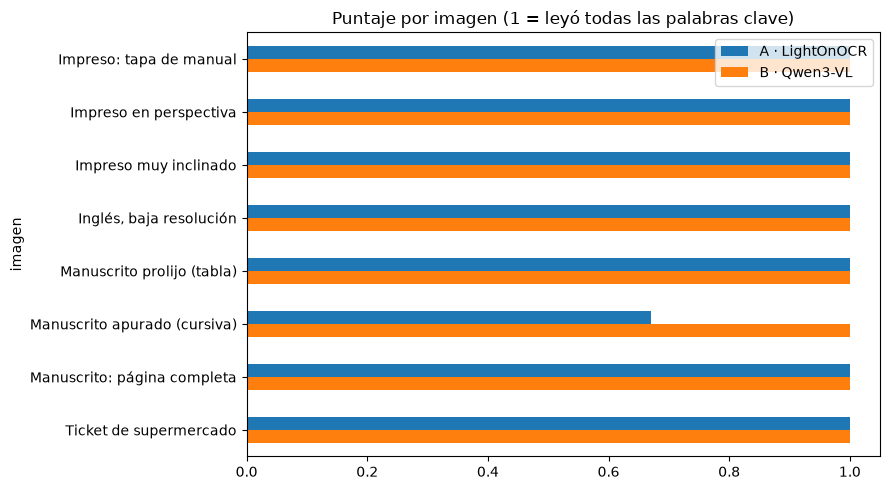

In [14]:
# Resumen de ambos
def resumen(res, info):
    con_puntaje = res
    dificiles = res["¿difícil?"] == "sí"
    return {
        "modelo": info["modelo"],
        "cómo corrió": info["forma"],
        "parámetros (miles de millones)": info["parametros_miles_de_millones"],
        "pesos en memoria (GB)": info["pesos_GB"],
        "carga (s)": info["carga_s"],
        "seg. promedio por imagen": round(res["segundos"].mean(), 2),
        "puntaje promedio": round(con_puntaje["puntaje"].mean(), 3),
        "aciertos (sí)": f'{(con_puntaje["¿acertó?"] == "sí").sum()} / {len(con_puntaje)}',
        "aciertos en casos difíciles": f'{(res[dificiles]["¿acertó?"] == "sí").sum()} / {dificiles.sum()}',
    }

tabla_resumen = pd.DataFrame([resumen(res_a, info_a), resumen(res_b, info_b)]).set_index("modelo").T
display(tabla_resumen)

# Comparación imagen por imagen
comp = pd.DataFrame({
    "imagen": res_a["imagen"],
    "A · LightOnOCR": res_a["puntaje"],
    "B · Qwen3-VL": res_b["puntaje"],
})
comp.plot.barh(x="imagen", figsize=(9, 5), title="Puntaje por imagen (1 = leyó todas las palabras clave)")
plt.xlim(0, 1.05); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

In [15]:
# Guardo los resultados para usarlos en el informe
os.makedirs("resultados", exist_ok=True)
res_a.assign(modelo=MODELO_A).to_csv("resultados/resultados_modelo_A.csv", index=False)
res_b.assign(modelo=MODELO_B).to_csv("resultados/resultados_modelo_B.csv", index=False)
tabla_resumen.to_csv("resultados/resumen_comparacion.csv")

## Resultados

Los dos modelos leyeron casi todas las palabras clave. LightOnOCR acertó 7 de 8 y Qwen 8 de 8. La única falla de LightOnOCR fue en la cursiva apurada: escribió "Ayedrez" en vez de "Ajedrez". Con esta medición, la diferencia entre los dos es chica.

**Mirando el texto completo aparecen errores que el puntaje no muestra:**

| Imagen | LightOnOCR | Qwen3-VL |
|---|---|---|
| Folleto en perspectiva | Confundió los títulos chicos: "Planta" por *Pisos*, "Buc Hombres" por *Machimbres*, "Compartidos" por *Compensados* | Casi perfecto ("tapecuá", "tapebica.com.ar") |
| Revista inclinada | Leyó bien los títulos, pero después **repitió en bucle** "MAD / Claves para construir con madera" muchas veces | Leyó todo, pero **inventó nombres** en los créditos de letra muy chica (por ejemplo "Víctor Ortega"), que no se pueden leer en la foto |
| Libro en inglés, borroso | Título bien; el cuerpo es **inventado** ("spreading a stamp shell over the grapevine…") | Lo mismo: título bien, cuerpo inventado |
| Tabla manuscrita | La devolvió **como tabla** (HTML), con filas y columnas correctas | La leyó por filas, sin estructura; **tradujo** "REPLICACIÓN" a *REPLICATION* |
| Página completa manuscrita | Errores de letras: "Teoría de Gortel", "ayudanz", "INTERIOR de la IA" | Casi perfecto ("Teorema de Gödel", "ajedrez de Turing") |
| Ticket | Cambió el dominio: "supermercedasdia.com.**br**" | Perfecto |

**Conclusiones:**
- En **impreso claro** los dos funcionan muy bien.
- En **manuscrito y fotos difíciles**, Qwen comete menos errores de letras. Tiene sentido: LightOnOCR se entrenó con documentos escaneados y PDFs, y su model card no menciona letra manuscrita.
- Cuando la imagen **no se puede leer** (el libro borroso, los créditos chicos), **los dos inventan** texto que parece real en lugar de avisar. Es el error más peligroso, porque no se nota a simple vista. También muestra una limitación de mi puntaje: si las palabras clave aparecen, el puntaje da 1 aunque el resto sea inventado.
- LightOnOCR devuelve **Markdown/HTML** (títulos con `#`, tablas, `![image]` donde hay fotos). Eso sirve para documentos, pero hay que limpiarlo si solo se quiere el texto.
- **Costo:** en mi compu (CPU), Qwen ocupa **8,9 GB** contra **2 GB**, tarda **14,5 s** en cargar contra **4,3 s**, y **140 s** por imagen contra **105 s**.

---
# El mismo llamado de dos formas: `pipeline` vs. `InferenceClient`

Hago exactamente el mismo pedido, con el mismo modelo (`LightOnOCR-2-1B`), la misma imagen y el mismo largo máximo de respuesta. Lo único que cambia es dónde se ejecuta el modelo:

| | `pipeline` | `InferenceClient` |
|---|---|---|
| ¿Dónde están los pesos? | Se descargan del Hub a **mi compu** | Quedan en los servidores del **proveedor** (Featherless AI, vía Hugging Face) |
| ¿Dónde se hace la inferencia? | En **mi compu** (CPU o GPU) | En los **servidores del proveedor** |
| ¿Qué viaja por internet? | Los pesos (una vez, ~2 GB) | La imagen (ida) y el texto (vuelta), **en cada pedido** |
| ¿Necesita token / créditos? | No | Sí |

Con `InferenceClient` la imagen no se manda como objeto de Python: se convierte a texto en **base64** y viaja dentro del mensaje, como si fuera un link (`data:image/png;base64,...`).

Imagen: imagenes\01_impreso_limpio.jpeg (960, 1280)


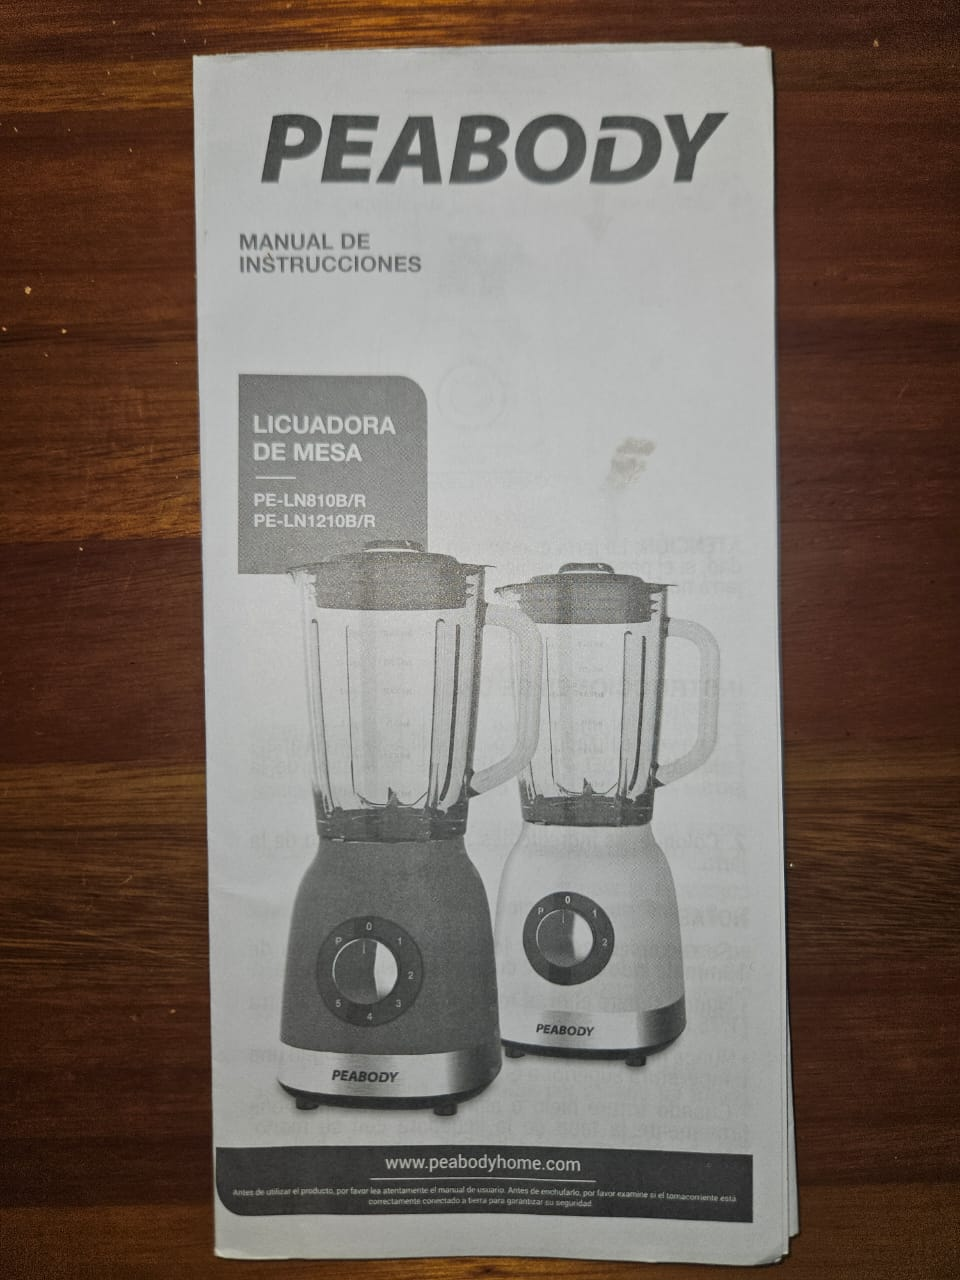

In [16]:
RUTA_PRUEBA = PRUEBAS[0][0]          # uso la tapa del manual (impreso limpio)
img_prueba = cargar_imagen(RUTA_PRUEBA)
print("Imagen:", RUTA_PRUEBA, img_prueba.size)
img_prueba

## Forma 1: con `pipeline` (corre en mi compu)

El modelo ya está cargado desde la Parte 1, así que acá mido solo la inferencia. El tiempo de carga ya lo medí antes (`info_a["carga_s"]`).

In [17]:
t0 = time.perf_counter()
salida_pipeline = pipe_a(text=armar_mensaje(MODELO_A, img_prueba),
                         max_new_tokens=MAX_TOKENS,
                         return_full_text=False)
seg_pipeline = time.perf_counter() - t0

print(f"⏱ pipeline: {seg_pipeline:.2f} s (más {info_a['carga_s']} s de carga la primera vez)\n")
print(salida_pipeline[0]["generated_text"])

[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


⏱ pipeline: 63.76 s (más 4.3 s de carga la primera vez)

# PEABODY

## MANUAL DE INSTRUCCIONES

### LICUADORA DE MESA

- PE-LN810B/R
- PE-LN1210B/R

![image](image_1.png)

PEABODY

PEABODY

www.peabodyhome.com

Antes de utilizar el producto, por favor lea atentamente el manual de usuario. Antes de enchufarlo, por favor examine si el tomacorriente está correctamente conectado a tierra para garantizar su seguridad.


## Forma 2: con `InferenceClient` (corre en los servidores de Hugging Face)

Uso la instancia `cliente` de la clase `InferenceClient` y llamo a su método `chat_completion`.

In [18]:
t0 = time.perf_counter()
salida_api = cliente.chat_completion(model=MODELO_A,
                                     messages=mensaje_api(MODELO_A, img_prueba),
                                     max_tokens=MAX_TOKENS)
seg_api = time.perf_counter() - t0

print(f"⏱ InferenceClient: {seg_api:.2f} s\n")
print(salida_api.choices[0].message.content)

⏱ InferenceClient: 5.64 s

# PEABODY

## MANUAL DE INSTRUCCIONES

### LICUADORA DE MESA

- PE-LN810B/R
- PE-LN1210B/R

![image](image_1.png)

PEABODY

PEABODY

www.peabodyhome.com

Antes de utilizar el producto, por favor lea atentamente el manual de usuario. Antes de enchufarlo, por favor examíane si el tomacorriente está correctamente conectado a tierra para garantizar su seguridad.


## Tiempos con todas las imágenes

Repito la comparación con todas las imágenes de prueba y saco el promedio para tener mas claro si es comportamiento usual o la demora fue con esa imagen especifica. Cada llamado a la API cuesta una fracción de centavo de dólar y tengo $5 usd cargados para hacer las pruebas.

In [19]:
filas = []
for ruta, desc, _, _ in PRUEBAS:
    img = cargar_imagen(ruta)

    t0 = time.perf_counter()
    s_pipe = pipe_a(text=armar_mensaje(MODELO_A, img), max_new_tokens=MAX_TOKENS, return_full_text=False)
    t_pipe = time.perf_counter() - t0

    t0 = time.perf_counter()
    s_api = cliente.chat_completion(model=MODELO_A, messages=mensaje_api(MODELO_A, img), max_tokens=MAX_TOKENS)
    t_api = time.perf_counter() - t0

    texto_pipe, texto_api = s_pipe[0]["generated_text"], s_api.choices[0].message.content
    filas.append({"imagen": desc,
                  "pipeline (s)": round(t_pipe, 2),
                  "InferenceClient (s)": round(t_api, 2),
                  "similitud entre las dos respuestas": round(difflib.SequenceMatcher(
                    None, normalizar(texto_pipe), normalizar(texto_api)).ratio(), 3)})
    print(f"✔ {desc:<32} pipeline {t_pipe:6.1f} s | InferenceClient {t_api:6.1f} s")

tiempos = pd.DataFrame(filas)
display(tiempos)
print(f"\nPromedio pipeline       : {tiempos['pipeline (s)'].mean():.2f} s por imagen (+ {info_a['carga_s']} s de carga inicial) · corre en {DISPOSITIVO}")
print(f"Promedio InferenceClient: {tiempos['InferenceClient (s)'].mean():.2f} s por imagen (sin carga: el modelo ya está prendido en el servidor)")
tiempos.to_csv("resultados/tiempos_pipeline_vs_inferenceclient.csv", index=False)

[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Impreso: tapa de manual          pipeline   63.5 s | InferenceClient    4.7 s


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Impreso en perspectiva           pipeline   93.7 s | InferenceClient    5.2 s


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

✔ Manuscrito: página completa      pipeline  108.8 s | InferenceClient    6.8 s


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✔ Ticket de supermercado           pipeline   87.2 s | InferenceClient    4.1 s


,imagen,pipeline (s),InferenceClient (s),similitud entre las dos respuestas
0,Impreso: tapa de manual,63.54,4.72,0.933
1,Impreso en perspectiva,93.73,5.24,0.290
2,Impreso muy inclinado,241.55,10.49,0.135
3,"Inglés, baja resolución",81.54,4.34,0.083
4,Manuscrito prolijo (tabla),112.51,7.93,0.998
5,Manuscrito apurado (cursiva),57.25,4.58,0.453
6,Manuscrito: página completa,108.75,6.80,0.875
7,Ticket de supermercado,87.20,4.08,0.855



Promedio pipeline       : 105.76 s por imagen (+ 4.3 s de carga inicial) · corre en CPU (sin GPU)
Promedio InferenceClient: 6.02 s por imagen (sin carga: el modelo ya está prendido en el servidor)


**Qué veo en los tiempos:**

- **`InferenceClient` fue unas muchisimo rápido: 6 s por imagen en promedio, contra 106 s con `pipeline` en mi compu. Mi computadora corre el modelo en la CPU, mientras que el servidor del proveedor usa GPUs preparadas para esto.
- Con `pipeline` además hay que sumar la carga del model* (4,3 s, más la descarga de ~2 GB la primera vez). Con `InferenceClient` no hay carga, porque el modelo ya está prendido en el servidor.
- Con `InferenceClient` cada imagen se paga. En la celda de la Parte 4 se ve que una imagen gastó 1.741 tokens (1.622 de entrada, casi todos de la imagen, y 119 de salida).
- No siempre dieron el mismo texto: En imágenes claras la similitud fue alta (tabla manuscrita 0,998; tapa del manual 0,93), pero en las difíciles fue muy baja (libro en inglés 0,08; revista inclinada 0,14). Es el mismo modelo con los mismos pesos, pero el proveedor puede correrlo con otra precisión numérica, otro programa (por ejemplo vLLM) y otros parámetros de generación. Cuando el modelo no lo tiene muy claro (texto borroso o inclinado), esas diferencias chicas cambian mucho el resultado. 

---
# Lectura del valor de retorno

Las dos formas devuelven el mismo texto, pero empaquetado distinto. Lo miro con `type()`:

In [20]:
print("── pipeline ──")
print("type(salida_pipeline)       →", type(salida_pipeline))
print("type(salida_pipeline[0])    →", type(salida_pipeline[0]))
print("claves                      →", list(salida_pipeline[0].keys()))
print("acceso al texto             → salida_pipeline[0]['generated_text']")
print()
print("── InferenceClient ──")
print("type(salida_api)                     →", type(salida_api))
print("type(salida_api.choices[0])          →", type(salida_api.choices[0]))
print("type(salida_api.choices[0].message)  →", type(salida_api.choices[0].message))
print("acceso al texto                      → salida_api.choices[0].message.content")
print("tokens usados (lo que se cobra)      →", salida_api.usage)

── pipeline ──
type(salida_pipeline)       → <class 'list'>
type(salida_pipeline[0])    → <class 'dict'>
claves                      → ['input_text', 'generated_text']
acceso al texto             → salida_pipeline[0]['generated_text']

── InferenceClient ──
type(salida_api)                     → <class 'huggingface_hub.inference._generated.types.chat_completion.ChatCompletionOutput'>
type(salida_api.choices[0])          → <class 'huggingface_hub.inference._generated.types.chat_completion.ChatCompletionOutputComplete'>
type(salida_api.choices[0].message)  → <class 'huggingface_hub.inference._generated.types.chat_completion.ChatCompletionOutputMessage'>
acceso al texto                      → salida_api.choices[0].message.content
tokens usados (lo que se cobra)      → ChatCompletionOutputUsage(completion_tokens=119, prompt_tokens=1622, total_tokens=1741, cached_tokens=0)


**Qué veo:**

- **`pipeline`** devuelve una **lista** (`list`) con un **diccionario** (`dict`) por cada resultado, con las claves `input_text` y `generated_text`. Al texto llego con **corchetes y clave**: `salida_pipeline[0]["generated_text"]`.
- **`InferenceClient`** devuelve un **objeto** de la clase `ChatCompletionOutput`. Adentro tiene otros objetos: `choices[0]` es un `ChatCompletionOutputComplete` y su `message` es un `ChatCompletionOutputMessage`. Al texto llego con **puntos (atributos)**: `salida_api.choices[0].message.content`.
- El objeto de `InferenceClient` trae además `usage`, con los tokens que se cobran: en este caso `prompt_tokens=1622`, `completion_tokens=119`, `total_tokens=1741`. Con `pipeline` no existe ese dato, porque no hay nada que cobrar.

---
# Resumen

In [21]:
print("Datos para la pregunta 6 del informe (pipeline vs. InferenceClient en la app):\n")
display(tabla_resumen)
print(f"\nDónde corrió pipeline                      : {DISPOSITIVO}")
print(f"Tiempo de carga de LightOnOCR con pipeline : {info_a['carga_s']} s")
print(f"Memoria que ocupan sus pesos               : {info_a['pesos_GB']} GB")
print(f"Inferencia promedio con pipeline           : {tiempos['pipeline (s)'].mean():.2f} s")
print(f"Inferencia promedio con InferenceClient    : {tiempos['InferenceClient (s)'].mean():.2f} s")

Datos para la pregunta 6 del informe (pipeline vs. InferenceClient en la app):



modelo,lightonai/LightOnOCR-2-1B,Qwen/Qwen3-VL-4B-Instruct
cómo corrió,pipeline,pipeline
parámetros (miles de millones),1.01,4.44
pesos en memoria (GB),2.01,8.88
carga (s),4.3,14.5
seg. promedio por imagen,104.98,139.87
puntaje promedio,0.959,1.0
aciertos (sí),7 / 8,8 / 8
aciertos en casos difíciles,4 / 5,5 / 5



Dónde corrió pipeline                      : CPU (sin GPU)
Tiempo de carga de LightOnOCR con pipeline : 4.3 s
Memoria que ocupan sus pesos               : 2.01 GB
Inferencia promedio con pipeline           : 105.76 s
Inferencia promedio con InferenceClient    : 6.02 s


In [22]:
# Al terminar, libero la memoria
del pipe_a
liberar()